# Actividad Prueba de Hipótesis
## Probabilidad y estadística
## Edilberto Antonio Gómez García

In [36]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
plt.style.use('dark_background')

In [87]:
datos = pd.read_csv('datos\\conjunto_de_datos_concentradohogar_enigh2024_ns.csv')
datos.columns

Index(['folioviv', 'foliohog', 'ubica_geo', 'tam_loc', 'est_socio', 'est_dis',
       'upm', 'factor', 'clase_hog', 'sexo_jefe',
       ...
       'mater_serv', 'material', 'servicio', 'deposito', 'prest_terc',
       'pago_tarje', 'deudas', 'balance', 'otras_erog', 'smg'],
      dtype='object', length=126)

In [88]:
datos = datos[['ing_cor', 'ubica_geo', 'factor', 'est_dis', 'upm', 'tot_integ']]
datos.head()

,ing_cor,ubica_geo,factor,est_dis,upm,tot_integ
0,138232.38,1001,207,1,1,4
1,118014.04,1001,207,1,1,4
2,46866.32,1001,207,1,1,2
3,110430.10,1001,207,1,1,4
4,99494.12,1001,196,2,2,4


In [89]:
display(datos.isna().sum())
display(datos.dtypes)

ing_cor      0
ubica_geo    0
factor       0
est_dis      0
upm          0
tot_integ    0
dtype: int64

ing_cor      float64
ubica_geo      int64
factor         int64
est_dis        int64
upm            int64
tot_integ      int64
dtype: object

In [90]:
datos['ubica_geo'] = datos['ubica_geo'].astype('str')
datos['ubica_geo'] = datos['ubica_geo'].str[:2]
datos['ubica_geo']

0        10
1        10
2        10
3        10
4        10
         ..
91409    32
91410    32
91411    32
91412    32
91413    32
Name: ubica_geo, Length: 91414, dtype: object

# Punto 1

In [91]:
datos_puebla = datos[datos['ubica_geo'] == '21']
datos_nl = datos[datos['ubica_geo'] == '19']
# a)
print(f'Hay {len(datos_puebla)} casas en Puebla')
print(f'Hay {len(datos_nl)} casas en Nuevo Leon')

Hay 2198 casas en Puebla
Hay 3796 casas en Nuevo Leon


In [9]:
# b)

muestra_puebla = len(datos_puebla)
muestra_nl = len(datos_nl)

media_puebla = datos_puebla['ing_cor'].mean()
media_nl = datos_nl['ing_cor'].mean()

var_puebla = datos_puebla['ing_cor'].var(ddof=1)
var_nl = datos_nl['ing_cor'].var(ddof=1)

desviacion_puebla = datos_puebla['ing_cor'].std(ddof=1)
desviacion_nl = datos_nl['ing_cor'].std(ddof=1)

mediana_puebla = datos_puebla['ing_cor'].median()
mediana_nl = datos_nl['ing_cor'].median()

print(f'Datos puebla:\nMedia: {media_puebla} \nVarianza: {var_puebla} \nDesviacion: {desviacion_puebla} \nMediana: {mediana_puebla}')
print(f'\nDatos NL: \nMedia: {media_nl} \nVarianza: {var_nl} \nDesviacion: {desviacion_nl} \nMediana: {mediana_nl}')

Datos puebla:
Media: 61341.043689717924 
Varianza: 2556039713.9587197 
Desviacion: 50557.291402514034 
Mediana: 47095.485

Datos NL: 
Media: 90808.35069810327 
Varianza: 92518768607.90863 
Desviacion: 304168.98035123275 
Mediana: 63817.115000000005


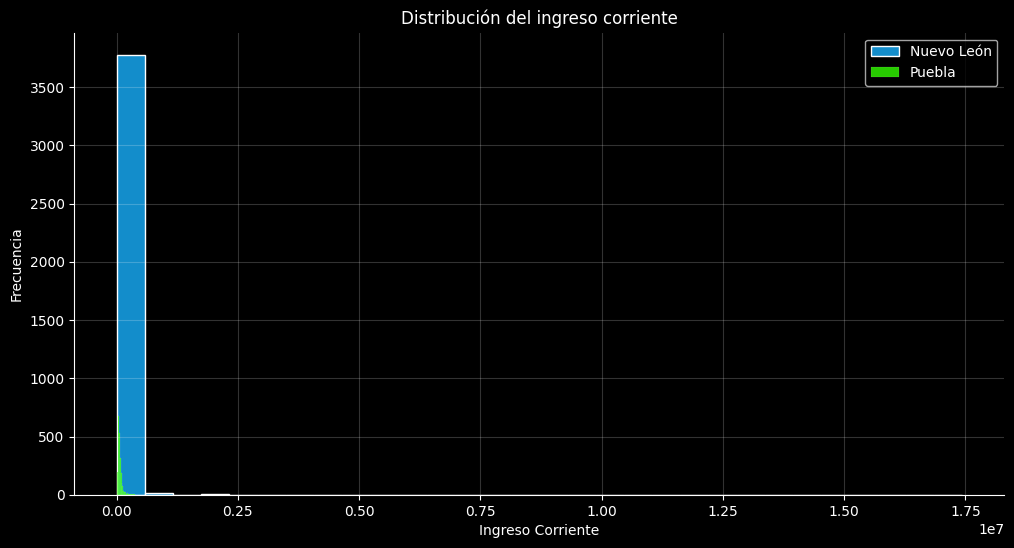

In [27]:
# c)
plt.figure(figsize=(12, 6))

sns.histplot(datos_nl['ing_cor'], color='#19B2FF', label='Nuevo León', alpha=0.8, bins=30)

sns.histplot(datos_puebla['ing_cor'], color='#32FF00', label='Puebla', alpha=0.8, bins=30)

plt.title('Distribución del ingreso corriente')
plt.xlabel('Ingreso Corriente')
plt.ylabel('Frecuencia')
plt.legend()
plt.grid(alpha=0.2)
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.show()

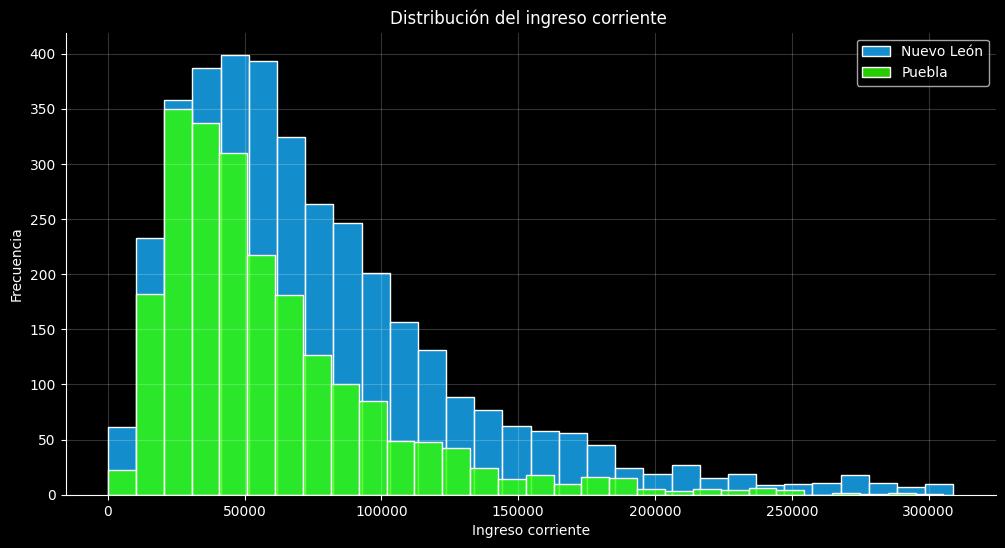

In [19]:
limite = datos['ing_cor'].quantile(0.99) # esto porque notamos un sesgo bastante alto hacia la derecha

plt.figure(figsize=(12, 6))

sns.histplot(datos_nl[datos_nl['ing_cor'] <= limite]['ing_cor'], color='#19B2FF', label='Nuevo León', alpha=0.8, bins=30)

sns.histplot(datos_puebla[datos_puebla['ing_cor'] <= limite]['ing_cor'], color='#32FF00', label='Puebla', alpha=0.8, bins=30)

plt.title('Distribución del ingreso corriente ')
plt.xlabel('Ingreso corriente')
plt.ylabel('Frecuencia')
plt.legend()
plt.grid(alpha=0.2)
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.show()

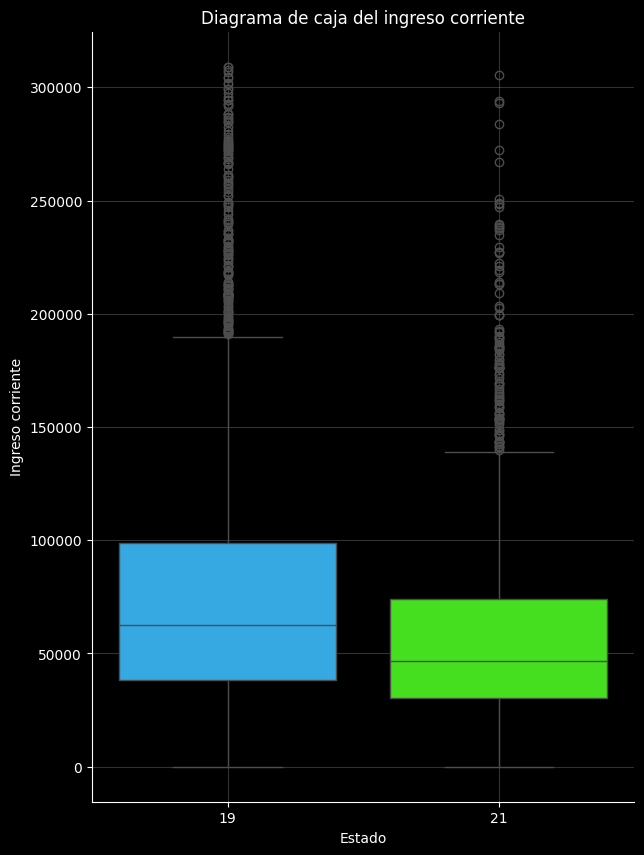

In [92]:
datos_comparativa = datos[datos['ubica_geo'].isin(['21', '19'])].copy()

datos_graficar = datos_comparativa[datos_comparativa['ing_cor'] <= limite] # para evitar los valores extremos que se observo anteriormente

plt.figure(figsize=(7, 10))

sns.boxplot(
    data=datos_graficar,
    x='ubica_geo',
    y='ing_cor',
    hue='ubica_geo',
    palette={'21': '#32FF00', '19': '#19B2FF'}
)

plt.title('Diagrama de caja del ingreso corriente')
plt.ylabel('Ingreso corriente')
plt.xlabel('Estado')
plt.grid(alpha=0.2)
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.show()

In [22]:
cuartiles_puebla = datos_puebla['ing_cor'].quantile([0.25, 0.75, 0.99])
cuartiles_nl = datos_nl['ing_cor'].quantile([0.25, 0.75, 0.99])

print(f'Cuartiles puebla: {cuartiles_puebla}')
print(f'\nCuartiles Nuevo León: {cuartiles_nl}')

Cuartiles puebla: 0.25     30419.9500
0.75     75333.2075
0.99    272849.2079
Name: ing_cor, dtype: float64

Cuartiles Nuevo León: 0.25     38722.3475
0.75    101777.4425
0.99    403176.3055
Name: ing_cor, dtype: float64


d)
Como se nota en el primer gráfico de histograma vemos que hay un fuerte sesgo positivo, por lo tanto, hay una la asimetria positiva, esto se nota más ára el estado de Nuevo León que para el de puebla ya que su dispersión (varianza o desviación estandar muestral) es mayor que la de puebla, al menos con estos cálculos, así como su percentil 99.

Esto puede afectar a los procedimientos de inferencia, ya que, si en una muestra existe un valor atípico altamente fuerte, y realizamos cálculos y demás, podremos llegar a dar conclusiones sobre la población en general que no serían correctas porque ese valor meteria mucho ruido (sesgo), desviando los parámetros de sus valores reales.

C:\Users\109149\AppData\Local\Temp\ipykernel_1532\427302384.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  datos_puebla['Y'] = np.log(1+datos_puebla['ing_cor'])
C:\Users\109149\AppData\Local\Temp\ipykernel_1532\427302384.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  datos_nl['Y'] = np.log(1+datos_nl['ing_cor'])


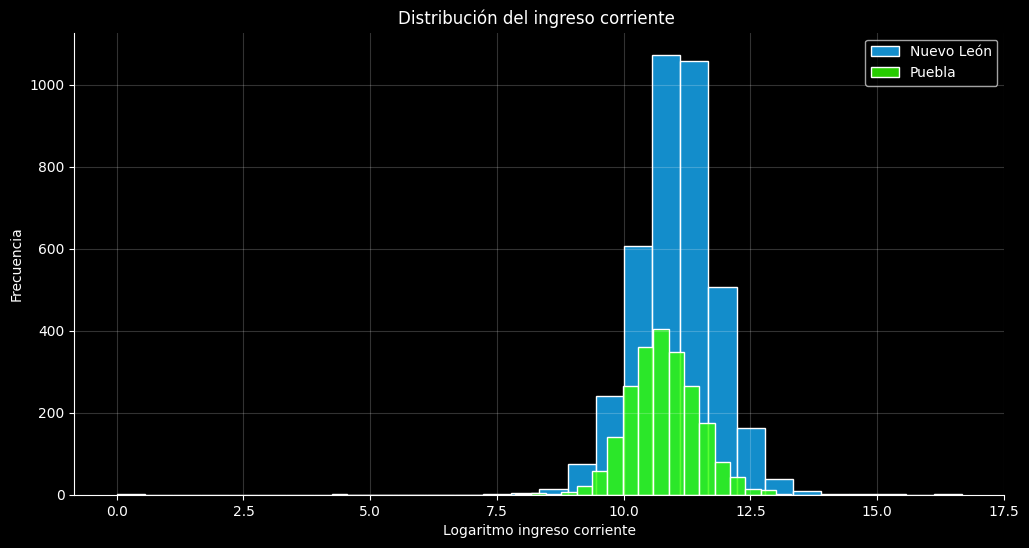

In [93]:
# e)
datos_puebla['Y'] = np.log(1+datos_puebla['ing_cor'])
datos_nl['Y'] = np.log(1+datos_nl['ing_cor'])

plt.figure(figsize=(12, 6))
sns.histplot(datos_nl['Y'], color='#19B2FF', label='Nuevo León', alpha=0.8, bins=30)
sns.histplot(datos_puebla['Y'], color='#32FF00', label='Puebla', alpha=0.8, bins=30)

plt.title('Distribución del ingreso corriente ')
plt.xlabel('Logaritmo ingreso corriente')
plt.ylabel('Frecuencia')
plt.legend()
plt.grid(alpha=0.2)
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.show()

Notamos que aquí ya no hizo falta determinar un limite para poder observar con claridad la distribución de los ingresos, además de que parece que ya no hay una asimetría muy notable.

## Punto 2

a) el parámetro de interés será el promedio, del estado de puebla. Las hipótesis serán:

$$
H_0: \mu_{puebla} = 60,000 \\
H_1: \mu_{puebla} \neq 60,000
$$

In [34]:
# b)
print(f'Datos puebla:\nMedia: {media_puebla} \nDesviacion muestral: {desviacion_puebla} \nTamaño de muestra: {muestra_puebla}')

Datos puebla:
Media: 61341.043689717924 
Desviacion muestral: 50557.291402514034 
Tamaño de muestra: 2198


In [105]:
# c)
# debido a que la varianza poblacional es deconocida para ello utilizaremos el estadistico T 

t_calc_1 = (media_puebla - 60000) / (desviacion_puebla/np.sqrt(muestra_puebla))
print(f'El estadistico es {t_calc_1}')

El estadistico es 1.2435778337018693


In [106]:
# d)
# como tenemos que nuestra hipotesis alternativa es diferente a algo, será una prueba bilateral, nuestras regiones de rechzao serán las menores a -t_alpha o mayores a t_alpha
alpha = 0.05
t_alpha = stats.t.ppf(1-alpha/2, df=muestra_puebla-1)
print(f"Región de rechazo: t_calc < {-t_alpha:.4f} o t_calc > {t_alpha:.4f}")

if abs(t_calc_1) > t_alpha:
    print('Se rechaza la hipotesis nula. ')
else:
    print('No se rechaza la hipotesis nula.')


Región de rechazo: t_calc < -1.9610 o t_calc > 1.9610
No se rechaza la hipotesis nula.


In [107]:
p1 = 2*(1-stats.t.cdf(abs(t_calc), df=muestra_puebla-1))

if p1 < alpha:
    print('Se rechaza la hipotesis nula.')
else:
    print('No se rechaza la hipotesis nula.')

No se rechaza la hipotesis nula.


f) Notamos que en ambos la hipótesis nula no se rechaza, por lo tanto, en el contexto del problema la interpretación es: Con un nivel de significancia del 0.05, no rechaza la hipotesis nula. No hay suficente evidencia estadisitica para mostrar que la media del ingreso corriente trimestral en Puebla es diferente a $60,000

# Punto 3

a) La formulación de las hipotesis son:

$$
H_0: \sigma_{puebla}^2 = 1 \\
H_1: \sigma_{puebla}^2 \neq 1
$$

In [51]:
# b)
varianza_m = datos_puebla['Y'].var(ddof=1)
varianza_m

np.float64(0.4808565506179718)

In [109]:
chi2_calc1 = (muestra_puebla - 1) * varianza_m / 1
chi2_calc1

np.float64(1056.441841707684)

In [110]:
# c)
alpha = 0.05
chi2_alpha_1 = stats.chi2.ppf(alpha/2, df=muestra_puebla-1)
chi2_alpha_2 = stats.chi2.ppf(1-alpha/2, df=muestra_puebla-1)
print(f"Región de rechazo: Chi2_calc < {chi2_alpha_1:.4f} o  Chi2_calc > {chi2_alpha_2:.4f}")

if (chi2_calc1 < chi2_alpha_1) or (chi2_calc1 > chi2_alpha_2):
    print('Se rechaza la hipotesis nula. ')
else:
    print('No se rechaza la hipotesis nula.')

Región de rechazo: Chi2_calc < 2068.9839 o  Chi2_calc > 2328.8044
Se rechaza la hipotesis nula. 


In [111]:
# d)
p_izq = stats.chi2.cdf(chi2_calc, df=muestra_puebla-1)
p_der = 1 - p_izq
# El valor p para una prueba de bilateral es el doble de la cola más pequeña
p2 = 2 * min(p_izq, p_der)

if p2 < alpha:
    print('Se rechaza la hipótesis nula.')
else:
    print('No se rechaza la hipótesis nula.')

Se rechaza la hipótesis nula.


En ambas se rechaza la hipótesis nula, por lo tanto en términos del problema: Con un nivel de significancia del 0.05 hay suficiente evidencia estadística para rechazar la hipotesis nula, es decir, que la varianza del logaritmo del ingreso trimestral más 1 es diferente de 1.

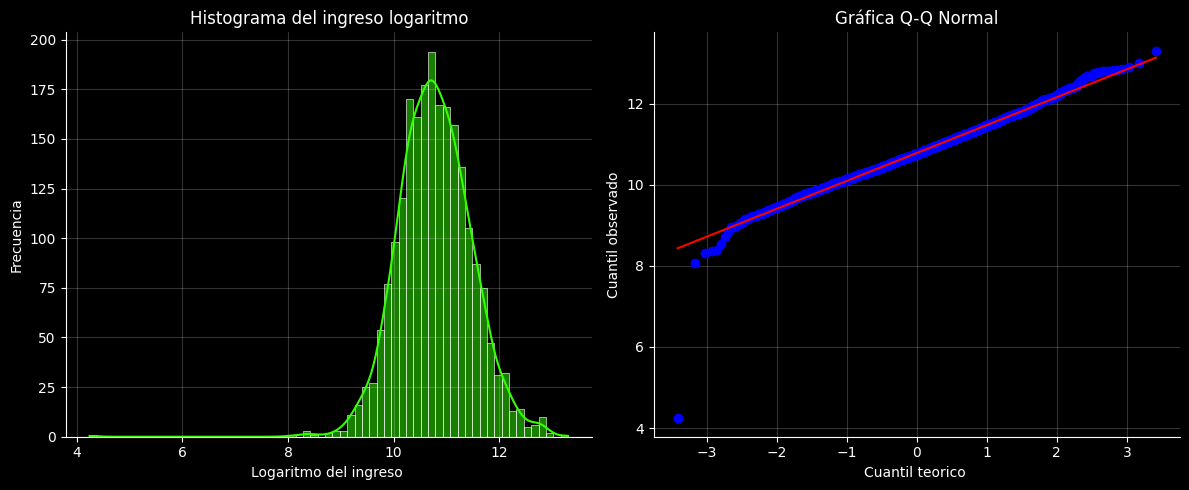

In [ ]:
# e)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.histplot(datos_puebla['Y'], kde=True, ax=axes[0], color='#32FF00')
axes[0].set_title('Histograma del ingreso logaritmo')
axes[0].set_xlabel('Logaritmo del ingreso ')
axes[0].set_ylabel('Frecuencia')
axes[0].grid(alpha=0.2)
axes[0].spines['top'].set_visible(False)
axes[0].spines['right'].set_visible(False)

stats.probplot(datos_puebla['Y'], dist="norm", plot=axes[1])
axes[1].set_title('Gráfica Q-Q Normal')
axes[1].set_xlabel('Cuantil teorico ')
axes[1].set_ylabel('Cuantil observado')
axes[1].grid(alpha=0.2)
axes[1].spines['top'].set_visible(False)
axes[1].spines['right'].set_visible(False)

plt.tight_layout()
plt.show()


Parece que resulta más tanta bien a primera vista que la transformación logarítmica logró corregir el sesgo positivo que habia en los ingresos, en el histograma parece que se ajusta a una normal, de igual manera los puntos azules en el gráfico Q-Q parecen siguen la tendencia de la linea roja (que es la teórica) bien, sólo que al principio unos puntos no llegan ajustarse tanto, pero la mayoria sí.

f) Si Y no sigue una distribución normal, nuestro estadistico de prueba en este caso *chi2_calc* caerá más frecuentemente en las regiones de rechazo, esto quiere decir que estariamos cometiendo más veces el error tipo 1, es decir, rechazar $H_0$ cuando este en realidad en verdadero.

# Punto 4

a)  La formulación de las hipotesis son:

$$
H_0: \frac{\sigma^2_{NL}}{\sigma^2_P} = 1\\
H_1: \frac{\sigma^2_{NL}}{\sigma^2_P} \neq 1
$$
con:
$$
\sigma^2_{NL}: \text{Varianza de Y de Nuevo Leon} \\
\sigma^2_{P}: \text{Varianza de Y de Puebla}

$$

In [68]:
# b)
var_puebla = datos_puebla['Y'].var(ddof=1)
var_nl = datos_nl['Y'].var(ddof=1)
print(f"Varianza muestral Puebla: {var_puebla:.4f}")
print(f"Varianza muestral Nuevo León: {var_nl:.4f}")

Varianza muestral Puebla: 0.4809
Varianza muestral Nuevo León: 0.6486


In [113]:
# c)
F_calc1 = var_nl / var_puebla
print(F_calc)

df1 = muestra_nl - 1
df2 = muestra_puebla - 1
print(f"Estadístico F: {F_calc:.4f}")
print(f"Grados de libertad: (NL)={df1}, (P)={df2}")

1.3487449447948612
Estadístico F: 1.3487
Grados de libertad: (NL)=3795, (P)=2197


In [116]:
# d)
alpha = 0.05
F_alpha_1 = stats.f.ppf(alpha / 2, dfn=df1, dfd=df2)
F_alpha_2 = stats.f.ppf(1 - (alpha / 2), dfn=df1, dfd=df2)
print(f"Región de rechazo: F_calc < {F_alpha_1:.4f} o F > {F_alpha_2:.4f}")

if (F_calc1 < F_alpha_1) or (F_calc1 > F_alpha_2):
    print('Se rechaza la hipotesis nula. ')
else:
    print('No se rechaza la hipotesis nula.')

Región de rechazo: F_calc < 0.9287 o F > 1.0776
Se rechaza la hipotesis nula. 


In [118]:
# e)
p_izq = stats.f.cdf(F_calc, dfn=df1, dfd=df2)
p_der = 1 - p_izq
p3 = 2 * min(p_izq, p_der)
print(f"Valor p: {p3:.4g}")

if p3 < alpha:
    print("Se rechaza H0.")
else:
    print("No se rechaza H0.")

Valor p: 7.772e-15
Se rechaza H0.


Conclusión: con un nivel de significancia de 0.05, se rechaza $H_0$, es decir, hay evidencia estadistica significativa en la diferencia entre la variabilidad del ingreso logaritmico entre el estado de Nuevo Leon y Puebla.

# Punto 5

a)  La formulación de las hipotesis son:

$$
H_0: \mu_{NL} \leq \mu_P\\
H_1: \mu_{NL} > \mu_P
$$
con:
$$
\mu_{NL}: \text{Promedio del ingreso corriente de Nuevo Leon} \\
\mu_P: \text{Promedio del ingreso corriente de Puebla}

$$


In [ ]:
# b)
print(f"Nuevo León -> Media: {media_nl:.2f}, Desv. Est: {desviacion_nl:.2f}")
print(f"Puebla     -> Media: {media_puebla:.2f}, Desv. Est: {desviacion_puebla:.2f}\n")

Nuevo León -> Media: 90808.35, Desv. Est: 304168.98
Puebla     -> Media: 61341.04, Desv. Est: 50557.29



In [77]:
# c)
error_estandar = np.sqrt((desviacion_nl**2/muestra_nl) + (desviacion_puebla**2/muestra_puebla))
t_welch = (media_nl - media_puebla) / error_estandar
t_welch

np.float64(5.831328021411092)

In [79]:
num_nu = error_estandar**4
den_nu = (((desviacion_nl**2 / muestra_nl)**2) / (muestra_nl - 1)) + (((desviacion_puebla**2 / muestra_puebla)**2) / (muestra_puebla - 1))
nu = num_nu / den_nu
nu

np.float64(4149.463483792591)

In [80]:
# d)
alpha = 0.05
# prueba unilateral de cola superior
t_alpha = stats.t.ppf(1 - alpha, df=nu)
print(f"Región de rechazo: T > {t_alpha:.4f}\n")

if t_welch > t_alpha:
    print('Se rechaza H_0')
else:
    print('No se rechaza H_0')


Región de rechazo: T > 1.6452

Se rechaza H_0


In [ ]:
# e)
p4 = 1-stats.t.cdf(abs(t_welch), df=nu)

if p4 < alpha:
    print('Se rechaza la hipotesis nula.')
else:
    print('No se rechaza la hipotesis nula.')

Se rechaza la hipotesis nula.


Interpretación: Con un nivel de significancia de 0.05, se rechaza H_0, es decir, hay suficiente evidencia estadística para decir que el ingreso poblacional de Nuevo León es mayor que la de Puebla 

# Punto 6

a)  La formulación de las hipotesis son:

$$
H_0: p \leq 0.25\\
H_1: p > 0.25
$$

In [101]:
# b)
hogares_numerosos = (datos_puebla['tot_integ'] >= 5).sum()
prop_calc = hogares_numerosos / muestra_puebla

print(f"Hogares en la muestra (n): {muestra_puebla}")
print(f"Hogares numerosos (éxitos): {hogares_numerosos}")
print(f"Proporción muestral (p_hat): {prop_calc:.4f}\n")

Hogares en la muestra (n): 2198
Hogares numerosos (éxitos): 561
Proporción muestral (p_hat): 0.2552



c) Si la hipotesis nula es cierta, es decir $p \leq 0.25$, entonces la variable $X$, que representa el conteo de hogares numerosos, sigue una distribución binomial con parámetro n (tamaño muestra) y p de 0.25, es decir, $X \sim \text{Bin}(n, 0.25)$

In [102]:
# d)
alpha = 0.05
prop_alpha = stats.binom.ppf(1 - alpha, muestra_puebla, 0.25)

print(f"Región de rechazo: prop_calc > {prop_alpha}\n")

if prop_calc > prop_alpha:
    print('Se rechaza H_0')
else:
    print('No se rechaza H_0')

Región de rechazo: prop_calc > 583.0

No se rechaza H_0


In [120]:
# e)
prueba = stats.binomtest(hogares_numerosos, muestra_puebla, p=0.25, alternative='greater')
p5 = prueba.pvalue

print(f"Valor p: {p_valor:.4g}")

if p5 < alpha:
    print("Se rechaza la H0.")
else:
    print("No se rechaza la H0.")

Valor p: 0.293
No se rechaza la H0.


Con un nivel de significancia del 0.05, no se rechaza la hipotesis nula, es decir, no hay suficiente evidencia estadísitica para afirmar que la proporción de hogares numerosos en Puebla sea mayor que el 25%

# Punto 7

In [121]:
columnas = ['problema','H_0', 'H_1', 'estadistico', 'distribución', 'region de rechazo', 'valor p', 'decisión', 'interpretación']
problema = ['Ingreso Puebla', 'Varianza Puebla', 'Varianza NL vs P', 'Medias NL vs P ', 'Hogares Puebla']
H_0 = ['mu = 60000', 'sigma^2 = 1', 'sigma^2_NL / sigma^2_P = 1', 'mu_NL <= mu_P', 'p <= 0.25']
H_1 = ['mu != 60000', 'sigma^2 != 1', 'sigma^2_NL / sigma^2_P != 1', 'mu_NL > mu_P', 'p > 0.25']
distribucion = ['T de Student', 'Chi-cuadrada',  'F de Fisher', 'T de Welch', 'Binomial']
region_de_rechazo = ['T < -tcrit o T > tcrit', 'Chi2 < Chi2_inf o Chi2 > Chi2_sup', 'F < F_inf o F > F_sup', 'T > tcrit', 'X > Xcrit']


estadistico = [t_calc_1, chi2_calc1, F_calc1, t_welch, prop_calc]
valor_p = [p1, p2, p3, p4, p5]
decision = ['No se rechaza', 'Se rechaza', 'Se rechaza', 'Se rechaza', 'No se rechaza']
interpretacion = ['No existe evidencia para afirmar que ingreso de puebla es diferente de $60,000',
                'Hay evidencia para afirmar que la varianza ingreso logaritmico del ingreso es diferente de 1', 
                'Hay evidencia para afirmar que la varianza ingreso de NL y de Puebla son diferentes', 
                'Hay evidencia para afirmar que la media del ingreso de NL es superir a la de Puebla', 
                'No hay evidencia para afirmar que la proporción de hogares numerosos en Puebla sea mayor que 0.25']

resumen = pd.DataFrame({
    'Problema': problema,
    'H_0': H_0,
    'H_1': H_1,
    'Estadístico': estadistico,
    'Distribución': distribucion,
    'Región de rechazo': region_de_rechazo,
    'Valor p': valor_p,
    'Decisión': decision,
    'Interpretación': interpretacion
})

resumen


,Problema,H_0,H_1,Estadístico,Distribución,Región de rechazo,Valor p,Decisión,Interpretación
0,Ingreso Puebla,mu = 60000,mu != 60000,1.243578,T de Student,T < -tcrit o T > tcrit,2.137877e-01,No se rechaza,No existe evidencia para afirmar que ingreso d...
1,Varianza Puebla,sigma^2 = 1,sigma^2 != 1,1056.441842,Chi-cuadrada,Chi2 < Chi2_inf o Chi2 > Chi2_sup,1.068176e-103,Se rechaza,Hay evidencia para afirmar que la varianza ing...
2,Varianza NL vs P,sigma^2_NL / sigma^2_P = 1,sigma^2_NL / sigma^2_P != 1,1.348745,F de Fisher,F < F_inf o F > F_sup,7.771561e-15,Se rechaza,Hay evidencia para afirmar que la varianza ing...
3,Medias NL vs P,mu_NL <= mu_P,mu_NL > mu_P,5.831328,T de Welch,T > tcrit,2.958556e-09,Se rechaza,Hay evidencia para afirmar que la media del in...
4,Hogares Puebla,p <= 0.25,p > 0.25,0.255232,Binomial,X > Xcrit,2.929686e-01,No se rechaza,No hay evidencia para afirmar que la proporció...


a. Economicamente, Nuevo Leon presenta un promedio más alto en ingresos que Puebla, también presenta una dispersión diferente en la riqueza de sus hogares. Demográficamente en Puebla la conecntración de hogares números representa 1/4 de sus hogares. 

b. Los supuestos que hace son los de normalidad en el logaritmo de los ingresos economicos, ya que sin el logaritmo, se presenta una fuerte asimetria positiva. Por lo tanto donde se presenta más discordancia sería en la cola superior debido a esos extremos que el logaritmo más o menos puede transformar bien.

c. Debido a que como se elevan al cuadrado la diferencias, al tener valores atípicos altemente extremos, esas diferencias son altas, pero aún más se vuelven cuando se elevan al cuadrado, lo que suma fuertemente a la varianza.

-----

Extra se añaden los ejercicios de python de las diapositivas

In [122]:
import seaborn as sns

# hipotesis nula: mu_primera >= mu_total
# hipotesis aleternativa mu_primera < mu_total, prueba de cola izquierda

titanic = sns.load_dataset('titanic')
titanic

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,male,27.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True
887,1,1,female,19.0,0,0,30.0000,S,First,woman,False,B,Southampton,yes,True
888,0,3,female,NaN,1,2,23.4500,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,0,30.0000,C,First,man,True,C,Cherbourg,yes,True


In [123]:
titanic.isna().sum()

survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

In [126]:
# hipotesis nula: mu_primera >= mu_total
# hipotesis aleternativa mu_primera < mu_total, prueba de cola izquierda

primera_clase = titanic[titanic['pclass']==1]

mu_total = titanic['age'].mean()
mu_primera = primera_clase['age'].mean()

print(mu_total, mu_primera)
print('\n')

std_total = titanic['age'].std(ddof=0)
std_primera = primera_clase['age'].std(ddof=1)

#print(std_total, std_primera)

#porque existe NaN
n_total = titanic['age'].count()
n_primera = primera_clase['age'].count()

#print(n_total, n_primera)


alpha = 0.05
z_alpha = stats.norm.ppf(alpha, loc=0, scale=1)
z = (mu_primera - mu_total)/(std_total/np.sqrt(n_primera))
print(z_alpha, z)
if z < z_alpha:
    print('Se rechaza H_0, la media de la primera clase es menor a la media total')
else:
    print('Se acepta H_0, la media de la primera clase es mayor o igual a la media total')

print('\n')

t_alpha = stats.t.ppf(alpha, n_primera-1)

T = (mu_primera - mu_total)/(std_primera/np.sqrt(n_primera))
print(t_alpha, T)
if T < t_alpha:
    print('Se rechaza H_0, la media de la primera clase es menor a la media total')
else:
    print('Se acepta H_0, la media de la primera clase es mayor o igual a la media total')


29.69911764705882 38.233440860215055


-1.6448536269514729 8.018054259930421
Se acepta H_0, la media de la primera clase es mayor o igual a la media total


-1.653131868631923 7.862851023885084
Se acepta H_0, la media de la primera clase es mayor o igual a la media total


In [127]:
# H_0: sigma^2 >= 64
# H_1: sigma^2 < 64

bills = sns.load_dataset('tips')
bills

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4
...,...,...,...,...,...,...,...
239,29.03,5.92,Male,No,Sat,Dinner,3
240,27.18,2.00,Female,Yes,Sat,Dinner,2
241,22.67,2.00,Male,Yes,Sat,Dinner,2
242,17.82,1.75,Male,No,Sat,Dinner,2


In [130]:
# H_0: sigma^2 >= 64
# H_1: sigma^2 < 64

varianza_muestral = bills['total_bill'].var(ddof=1)
print(varianza_muestral)
varianza_poblacional = 64
n = bills['total_bill'].count()

alpha = 0.05

chi2_alpha = stats.chi2.ppf(alpha, n-1)
chi2 = ((n-1)*varianza_muestral)/varianza_poblacional


if chi2 < chi2_alpha:
    print('Se rechaza H_0, la varianza de las cuentas totales ha aumentado o se ha mantenido')
else:
    print('Se acepta H_0, la varianza de la cuentas totales ha disminuido')

79.25293861397827
Se acepta H_0, la varianza de la cuentas totales ha disminuido
